# Introvert vs. Extrovert: Exploratory Data Analysis

**Project goal:** determine whether the available survey dataset is sufficient for the planned scrollytelling webpage, or whether supplemental data is necessary.

The evaluation below considers:
- dataset size and missing/duplicate records
- class balance and population-context coverage
- whether the variables contain clear, useful personality differences
- redundancy among variables
- whether findings are strong enough for a first prototype


In [13]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

data_path = Path("data/personality_dataset.csv")
df = pd.read_csv(data_path)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("Columns:", ", ".join(df.columns))
df.head()


Rows: 2,900
Columns: 8
Columns: Time_spent_Alone, Stage_fear, Social_event_attendance, Going_outside, Drained_after_socializing, Friends_circle_size, Post_frequency, Personality


,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.000,No,4.000,6.000,No,13.000,5.000,Extrovert
1,9.000,Yes,0.000,0.000,Yes,0.000,3.000,Introvert
2,9.000,Yes,1.000,2.000,Yes,5.000,2.000,Introvert
3,0.000,No,6.000,7.000,No,14.000,8.000,Extrovert
4,3.000,No,9.000,4.000,No,8.000,5.000,Extrovert


## 1. Data quality and completeness

In [2]:
missing = df.isna().sum()
missing_pct = 100 * missing / len(df)
quality = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct,
    "unique_values": df.nunique(dropna=True)
})
display(quality)

print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Rows missing at least one value: {df.isna().any(axis=1).sum():,}")
print(f"Rows missing no values: {df.notna().all(axis=1).sum():,}")

df.info()


,missing_count,missing_pct,unique_values
Time_spent_Alone,63,2.172,12
Stage_fear,73,2.517,2
Social_event_attendance,62,2.138,11
Going_outside,66,2.276,8
Drained_after_socializing,52,1.793,2
Friends_circle_size,77,2.655,16
Post_frequency,65,2.241,11
Personality,0,0.000,2


Duplicate rows: 388
Rows missing at least one value: 423
Rows missing no values: 2,477
<class 'pandas.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2837 non-null   float64
 1   Stage_fear                 2827 non-null   str    
 2   Social_event_attendance    2838 non-null   float64
 3   Going_outside              2834 non-null   float64
 4   Drained_after_socializing  2848 non-null   str    
 5   Friends_circle_size        2823 non-null   float64
 6   Post_frequency             2835 non-null   float64
 7   Personality                2900 non-null   str    
dtypes: float64(5), str(3)
memory usage: 221.4 KB


**Interpretation:** Missingness is small and mostly per-column. It is not necessarily a reason to add another dataset: listwise deletion or sensible imputation can preserve most of the sample. Duplicate rows should be checked because a synthetic or copied source may inflate apparent sample size.


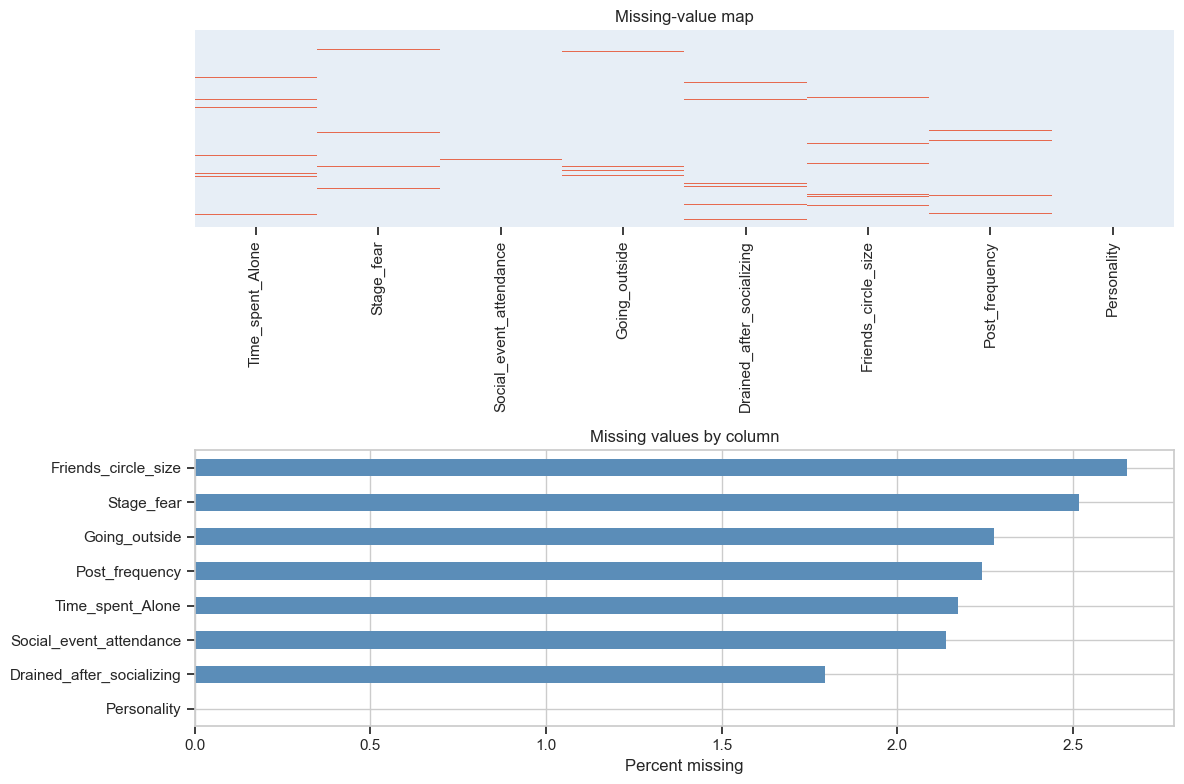

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [1, 1.4]})

sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#E7EEF6", "#E66A50"], ax=axes[0])
axes[0].set_title("Missing-value map")

quality["missing_pct"].sort_values().plot.barh(ax=axes[1], color="#5B8DB8")
axes[1].set_xlabel("Percent missing")
axes[1].set_title("Missing values by column")
plt.tight_layout()


## 2. Target balance

,count,percent
Personality,,
Extrovert,1491,51.414
Introvert,1409,48.586


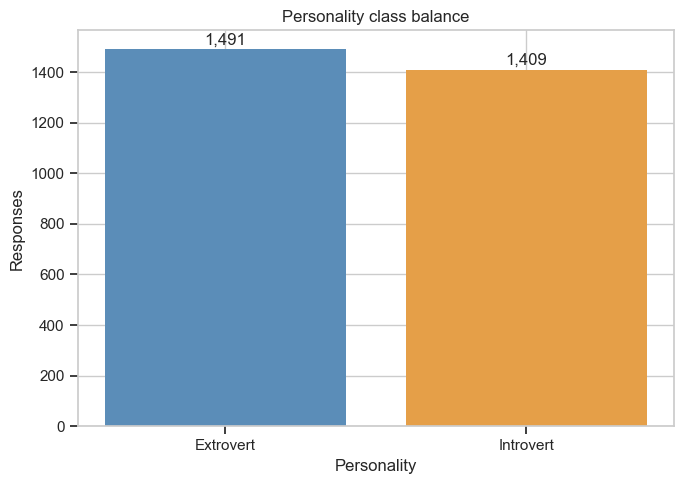

In [4]:
class_counts = df["Personality"].value_counts(dropna=False)
class_pct = 100 * df["Personality"].value_counts(normalize=True)

balance = pd.DataFrame({"count": class_counts, "percent": class_pct})
display(balance)

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#5B8DB8", "#E59F48"]
ax.bar(balance.index.astype(str), balance["count"], color=colors)
ax.set_title("Personality class balance")
ax.set_xlabel("Personality")
ax.set_ylabel("Responses")
for index, count in enumerate(balance["count"]):
    ax.text(index, count + 20, f"{count:,}", ha="center")
plt.tight_layout()


**Interpretation:** The target classes should be balanced enough to support fair descriptive comparisons. Do not rely on a large class-size difference to explain differences in visualized patterns.


## 3. Numeric variable distributions

,count,mean,std,min,25%,50%,75%,max
Time_spent_Alone,"2,837.000",4.506,3.479,0.000,2.000,4.000,8.000,11.000
Social_event_attendance,"2,838.000",3.963,2.904,0.000,2.000,3.000,6.000,10.000
Going_outside,"2,834.000",3.000,2.247,0.000,1.000,3.000,5.000,7.000
Friends_circle_size,"2,823.000",6.269,4.290,0.000,3.000,5.000,10.000,15.000
Post_frequency,"2,835.000",3.565,2.927,0.000,1.000,3.000,6.000,10.000


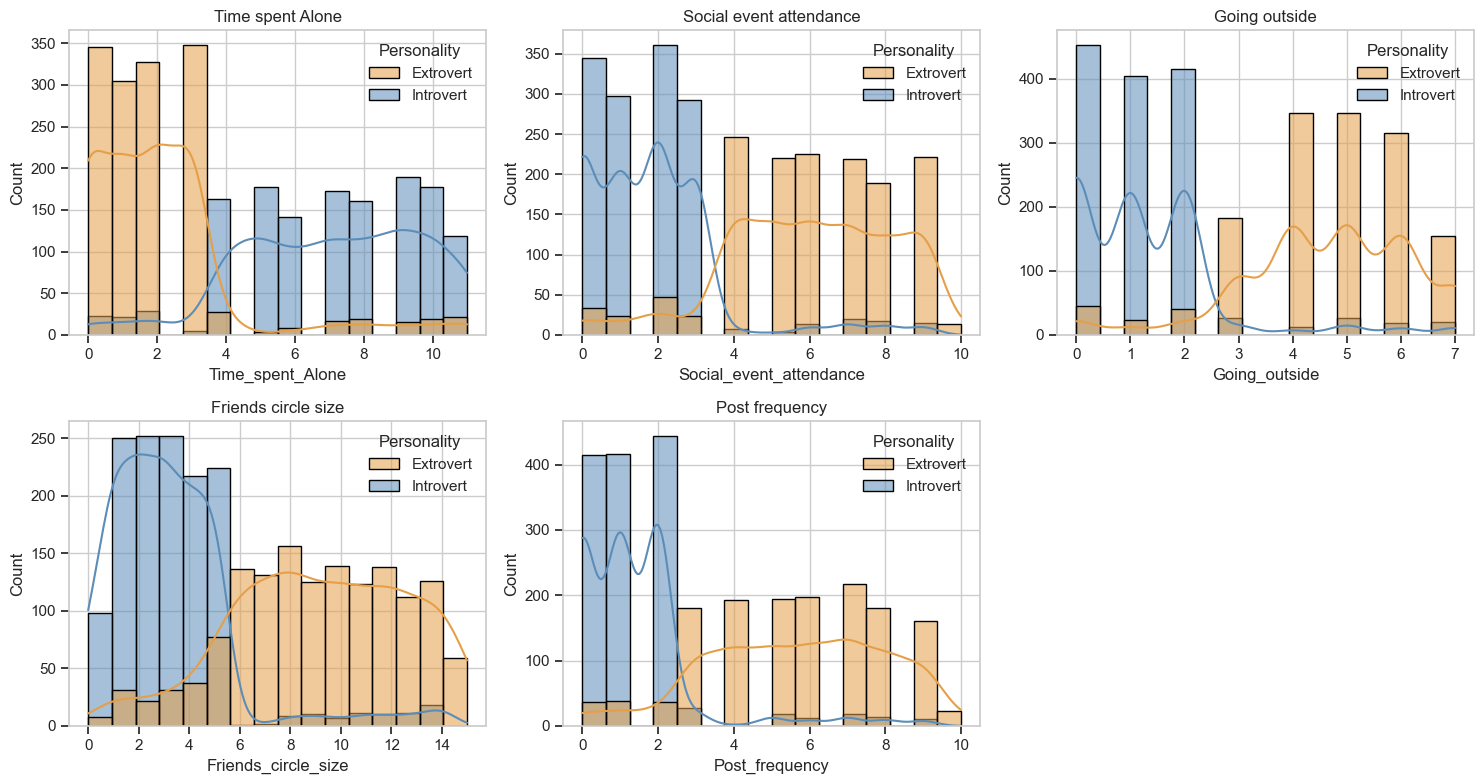

In [5]:
numeric = [
    "Time_spent_Alone",
    "Social_event_attendance",
    "Going_outside",
    "Friends_circle_size",
    "Post_frequency",
]

display(df[numeric].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, column in zip(axes, numeric):
    sns.histplot(data=df, x=column, hue="Personality", bins=16,
                 kde=True, palette={"Introvert": "#5B8DB8", "Extrovert": "#E59F48"},
                 alpha=0.55, ax=ax)
    ax.set_title(column.replace("_", " "))
axes[-1].axis("off")
plt.tight_layout()


## 4. Personality differences

Personality,Extrovert,Introvert
Time_spent_Alone,2.067,7.080
Social_event_attendance,6.016,1.779
Going_outside,4.635,1.273
Friends_circle_size,9.174,3.197
Post_frequency,5.639,1.369


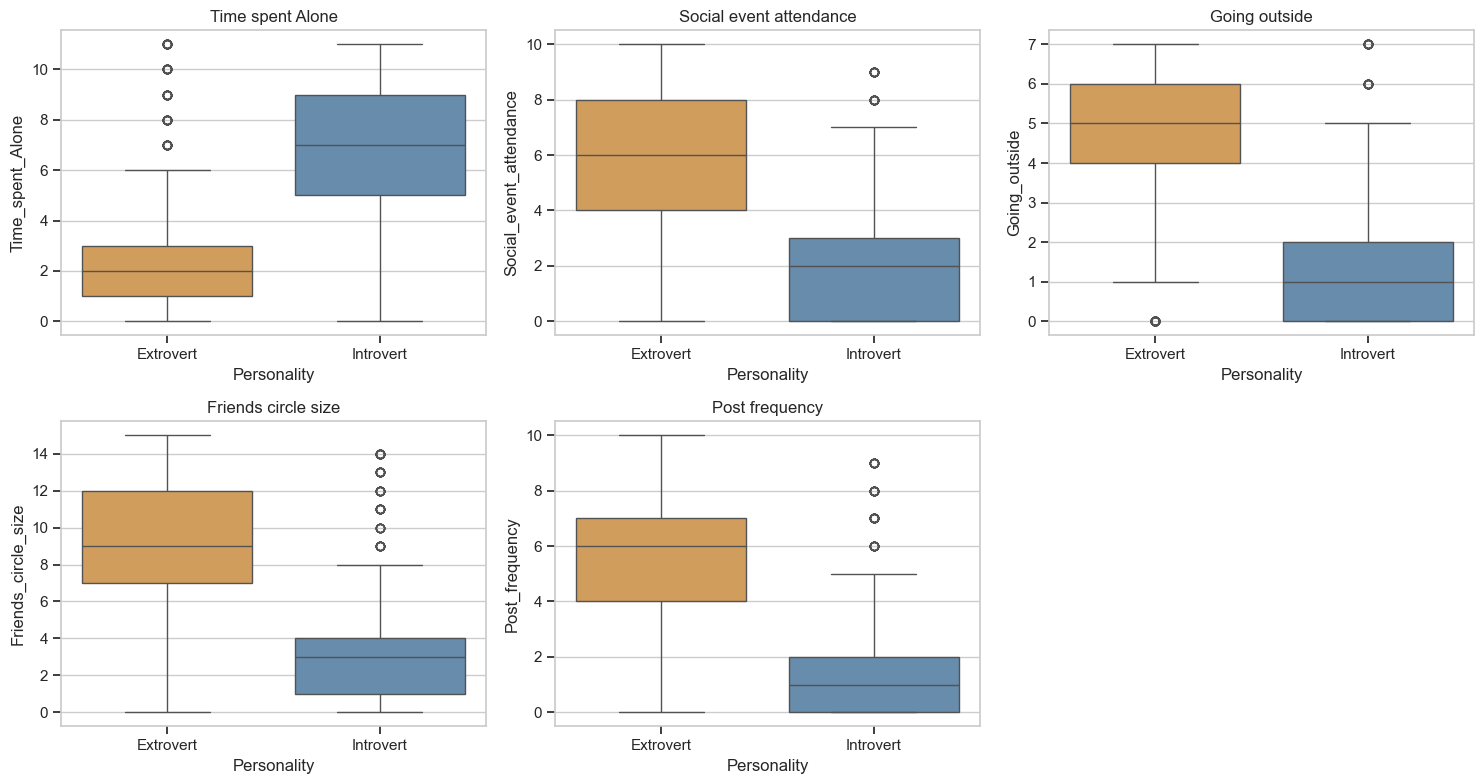

In [6]:
group_means = df.groupby("Personality")[numeric].mean().T
display(group_means)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=False)
axes = axes.ravel()
for ax, column in zip(axes, numeric):
    sns.boxplot(data=df, x="Personality", y=column, hue="Personality",
                palette={"Introvert": "#5B8DB8", "Extrovert": "#E59F48"},
                legend=False, ax=ax)
    ax.set_title(column.replace("_", " "))
axes[-1].axis("off")
plt.tight_layout()


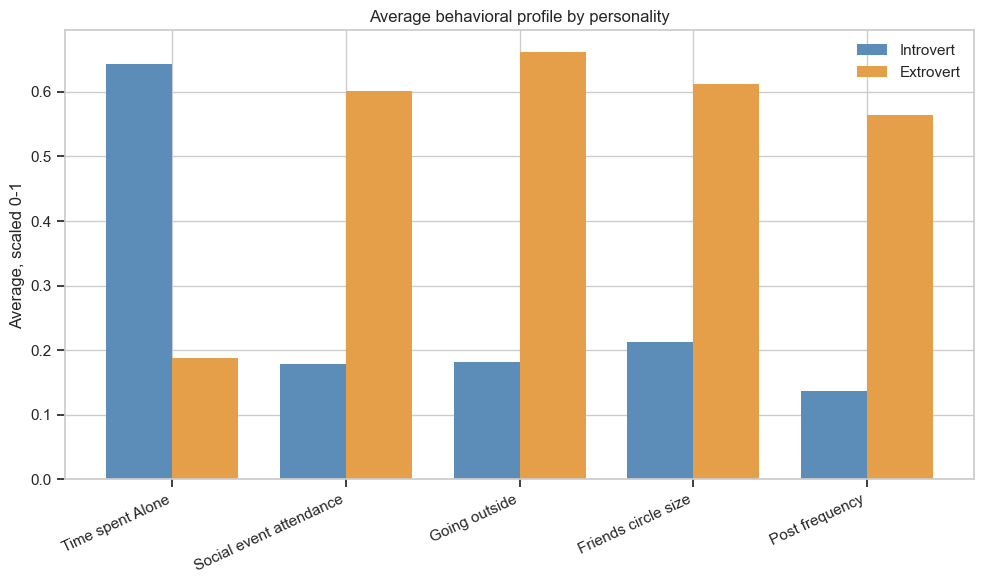

In [7]:
# Normalized group profiles make all variables comparable on one visual.
normalized = df[numeric].join(df["Personality"]).groupby("Personality").mean()
normalized = (normalized - df[numeric].min()) / (df[numeric].max() - df[numeric].min())

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(numeric))
width = 0.38

ax.bar(x - width/2, normalized.loc["Introvert"], width,
       label="Introvert", color="#5B8DB8")
ax.bar(x + width/2, normalized.loc["Extrovert"], width,
       label="Extrovert", color="#E59F48")
ax.set_xticks(x, [column.replace("_", " ") for column in numeric], rotation=25, ha="right")
ax.set_ylabel("Average, scaled 0-1")
ax.set_title("Average behavioral profile by personality")
ax.legend()
plt.tight_layout()


## 5. Binary behavior variables

Personality,Extrovert %,Introvert %
Stage_fear,,
No,92.340,5.733
Yes,7.660,94.267


Personality,Extrovert %,Introvert %
Drained_after_socializing,,
No,92.464,5.745
Yes,7.536,94.255


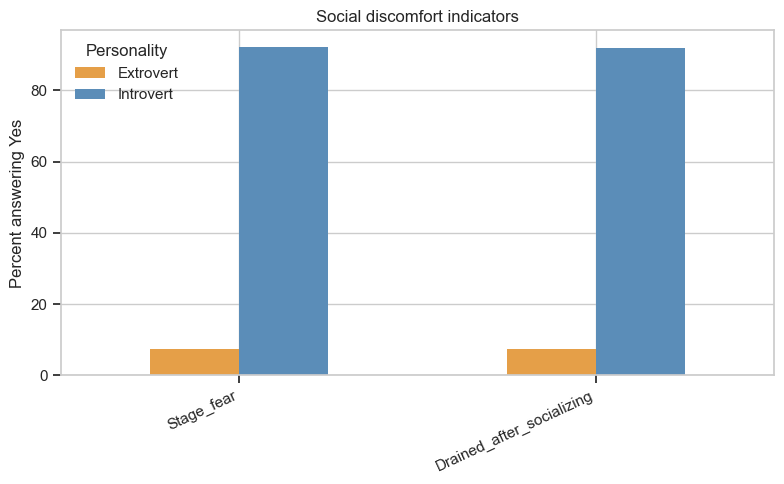

In [8]:
binary_columns = ["Stage_fear", "Drained_after_socializing"]

for column in binary_columns:
    ctab = pd.crosstab(df[column], df["Personality"], normalize="columns") * 100
    display(ctab.rename(columns={"Introvert": "Introvert %", "Extrovert": "Extrovert %"}))

binary_pct = (
    df.groupby("Personality")[binary_columns]
      .apply(lambda frame: (frame == "Yes").mean() * 100)
      .T
)

binary_pct.plot(kind="bar", figsize=(8, 5), color={"Introvert": "#5B8DB8", "Extrovert": "#E59F48"})
plt.ylabel("Percent answering Yes")
plt.title("Social discomfort indicators")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()


## 6. Relationships and redundancy

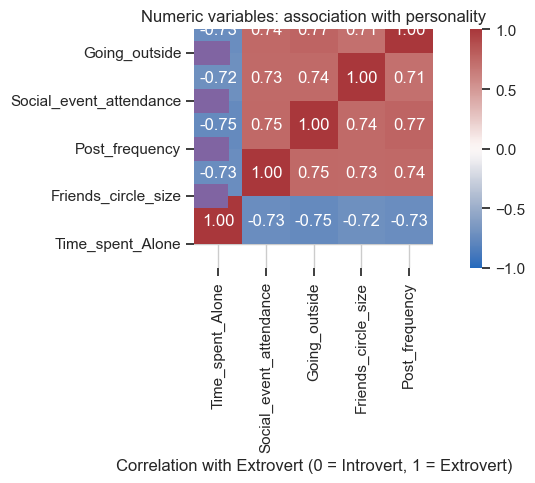

In [9]:
corr = df[numeric].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation among numeric variables")
plt.tight_layout()

# Encode the target as a numeric indicator for point-biserial correlations.
target_binary = (df["Personality"] == "Extrovert").astype(int)
effects = {}
for column in numeric:
    pair = pd.DataFrame({"x": df[column], "y": target_binary}).dropna()
    effects[column] = pointbiserialr(pair["x"], pair["y"]).statistic
effects = pd.Series(effects).sort_values()

effects.plot.barh(figsize=(8, 5), color="#8064A2")
plt.xlabel("Correlation with Extrovert (0 = Introvert, 1 = Extrovert)")
plt.title("Numeric variables: association with personality")
plt.tight_layout()


## 7. Potential outliers

In [10]:
outlier_summary = []
for column in numeric:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((values < low) | (values > high)).sum()
    outlier_summary.append({
        "variable": column,
        "IQR_low": low,
        "IQR_high": high,
        "outlier_count": count,
        "outlier_pct": 100 * count / len(values)
    })

display(pd.DataFrame(outlier_summary).set_index("variable").round(3))


,IQR_low,IQR_high,outlier_count,outlier_pct
variable,,,,
Time_spent_Alone,-7.000,17.000,0,0.000
Social_event_attendance,-4.000,12.000,0,0.000
Going_outside,-5.000,11.000,0,0.000
Friends_circle_size,-7.500,20.500,0,0.000
Post_frequency,-6.500,13.500,0,0.000


## 8. Sufficiency assessment

Use the following evidence-based checklist for a first scrollytelling prototype:

- **Narrative coverage:** 2900-scale data can support several comparison and distribution stories.
- **Missingness:** assess the missing percentages and duplicate count above.
- **Balance:** a materially imbalanced target may limit how fairly the two groups are compared.
- **Behavioral signal:** strong separation in this dataset is useful for visual storytelling.
- **Context:** the source description is limited; there are no clear demographic or geographic columns. It should not be presented as representative of all introverts.

The final decision is printed below and can be reproduced whenever the dataset changes.


In [11]:
missing_pct_max = quality["missing_pct"].max()
duplicate_pct = 100 * df.duplicated().sum() / len(df)
smallest_class_pct = class_pct.min()
strongest_numeric_signal = abs(pd.Series(effects)).max()
has_relevant_binary_variables = all(column in df.columns for column in binary_columns)

# A prototype is sufficient if it has ample records, acceptable missingness,
# comparable classes, and a clear behavioral signal.
prototype_ready = (
    len(df) >= 1000
    and missing_pct_max <= 10
    and smallest_class_pct >= 35
    and strongest_numeric_signal >= 0.35
    and has_relevant_binary_variables
)

# Population/generalizability claims require context columns or an independent source.
supplement_needed_for_general_claims = (
    not any(column.lower() in {"age", "country", "gender", "geography", "location"}
            for column in df.columns)
)

print("=== SUPPLEMENTAL-DATA DECISION ===")
if prototype_ready:
    print("Prototype/EDA verdict: NO supplemental data is needed for the first prototype.")
else:
    print("Prototype/EDA verdict: Supplemental data is recommended before building the full visualization.")

if supplement_needed_for_general_claims:
    print("General-population claim verdict: YES — supplement with an independent, context-rich dataset.")
    print("Reason: the file does not provide age, location/geography, or other demographic context.")
else:
    print("General-population claim verdict: May be sufficient for claims confined to the represented population.")

print(f"Rows: {len(df):,}")
print(f"Largest missing-column percentage: {missing_pct_max:.2f}%")
print(f"Duplicate-row percentage: {duplicate_pct:.2f}%")
print(f"Smallest class percentage: {smallest_class_pct:.2f}%")
print(f"Strongest numeric association with personality: {strongest_numeric_signal:.3f}")


=== SUPPLEMENTAL-DATA DECISION ===
Prototype/EDA verdict: NO supplemental data is needed for the first prototype.
General-population claim verdict: YES — supplement with an independent, context-rich dataset.
Reason: the file does not provide age, location/geography, or other demographic context.
Rows: 2,900
Largest missing-column percentage: 2.66%
Duplicate-row percentage: 13.38%
Smallest class percentage: 48.59%
Strongest numeric association with personality: 0.748


## Final takeaway

The notebook should be treated as a decision report, not merely a collection of plots:

- **For the prototype:** use this dataset to develop the scrollytelling structure and compare core behaviors.
- **For broad conclusions:** do not describe the respondents as representative of all people or all introverts without a source for that representation.
- **For the second data pass:** if the project is to claim generalizability, seek independent, non-synthetic survey data with demographics and survey methodology.
- **For the visualization:** emphasize patterns in the recorded behaviors, explicitly label the data as a survey sample, and avoid treating personality as a rigid category.
